In [36]:
import pandas as pd
df=pd.read_csv("../01_data/02_processed/customer_churn_data_cleaned.csv ")

In [37]:
X=df.drop(columns=["customerID","Churn"])
Y=df["Churn"]

In [38]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,
test_size=0.2,random_state=42,stratify=Y)

In [39]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Create the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# 2. Train it
baseline_model.fit(X_train, Y_train)

# 3. Predict on test data
baseline_pred = baseline_model.predict(X_test)

# 4. Evaluate
print("Baseline Accuracy:", accuracy_score(Y_test, baseline_pred))
print(classification_report(Y_test, baseline_pred, zero_division=0))

Baseline Accuracy: 0.7345635202271115
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



In [40]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# 1. Create Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
params = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_leaf_nodes":[None,5,10,20],
    "class_weight": [None, "balanced"]
}



grid = GridSearchCV(
   estimator=DecisionTreeClassifier(random_state=42),
    param_grid=params,
    cv=skf,
    scoring="f1",
    n_jobs=-1
)
grid.fit(X_train, Y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1-score:", grid.best_score_)

model = grid.best_estimator_

Best Parameters: {'class_weight': 'balanced', 'max_depth': 7, 'max_leaf_nodes': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1-score: 0.6217827635361113


In [41]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(Y_test, y_pred))

print(confusion_matrix(Y_test, y_pred))

print(classification_report(Y_test, y_pred))

Accuracy: 0.7544357700496807
[[767 268]
 [ 78 296]]
              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.77      1409



In [42]:
train_accuracy = model.score(X_train, Y_train)

test_accuracy = model.score(X_test, Y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.7557685481008165
Testing Accuracy: 0.7544357700496807


In [43]:
tree = model.tree_

for node in range(tree.node_count):
    if tree.children_left[node] != tree.children_right[node]:
        feature = X_train.columns[tree.feature[node]]
        threshold = tree.threshold[node]

        print("Node:", node)
        print("Feature:", feature)
        print("Threshold:", threshold)
        print("Gini impurity:", tree.impurity[node])
        print()

Node: 0
Feature: Contract
Threshold: 0.5
Gini impurity: 0.5000000000001

Node: 1
Feature: InternetService
Threshold: 1.5
Gini impurity: 0.43947880852801957

Node: 2
Feature: MonthlyCharges
Threshold: 93.67499923706055
Gini impurity: 0.27592407853751566

Node: 3
Feature: tenure
Threshold: 5.5
Gini impurity: 0.4995876589319116

Node: 4
Feature: tenure
Threshold: 13.5
Gini impurity: 0.35163321285255345

Node: 5
Feature: TechSupport
Threshold: 0.5
Gini impurity: 0.45450278752695406

Node: 6
Feature: PhoneService
Threshold: 0.5
Gini impurity: 0.4728964652558496

Node: 8
Feature: PaymentMethod
Threshold: 0.5
Gini impurity: 0.44272752092624834

Node: 9
Feature: OnlineSecurity
Threshold: 0.5
Gini impurity: 0.18311745639758736

Node: 10
Feature: Contract
Threshold: 1.5
Gini impurity: 0.4406000703907025

Node: 12
Feature: TotalCharges
Threshold: 21.0
Gini impurity: 0.49985229285939425

Node: 14
Feature: TotalCharges
Threshold: 7755.599853515625
Gini impurity: 0.3106995562106125

Node: 15
Feature

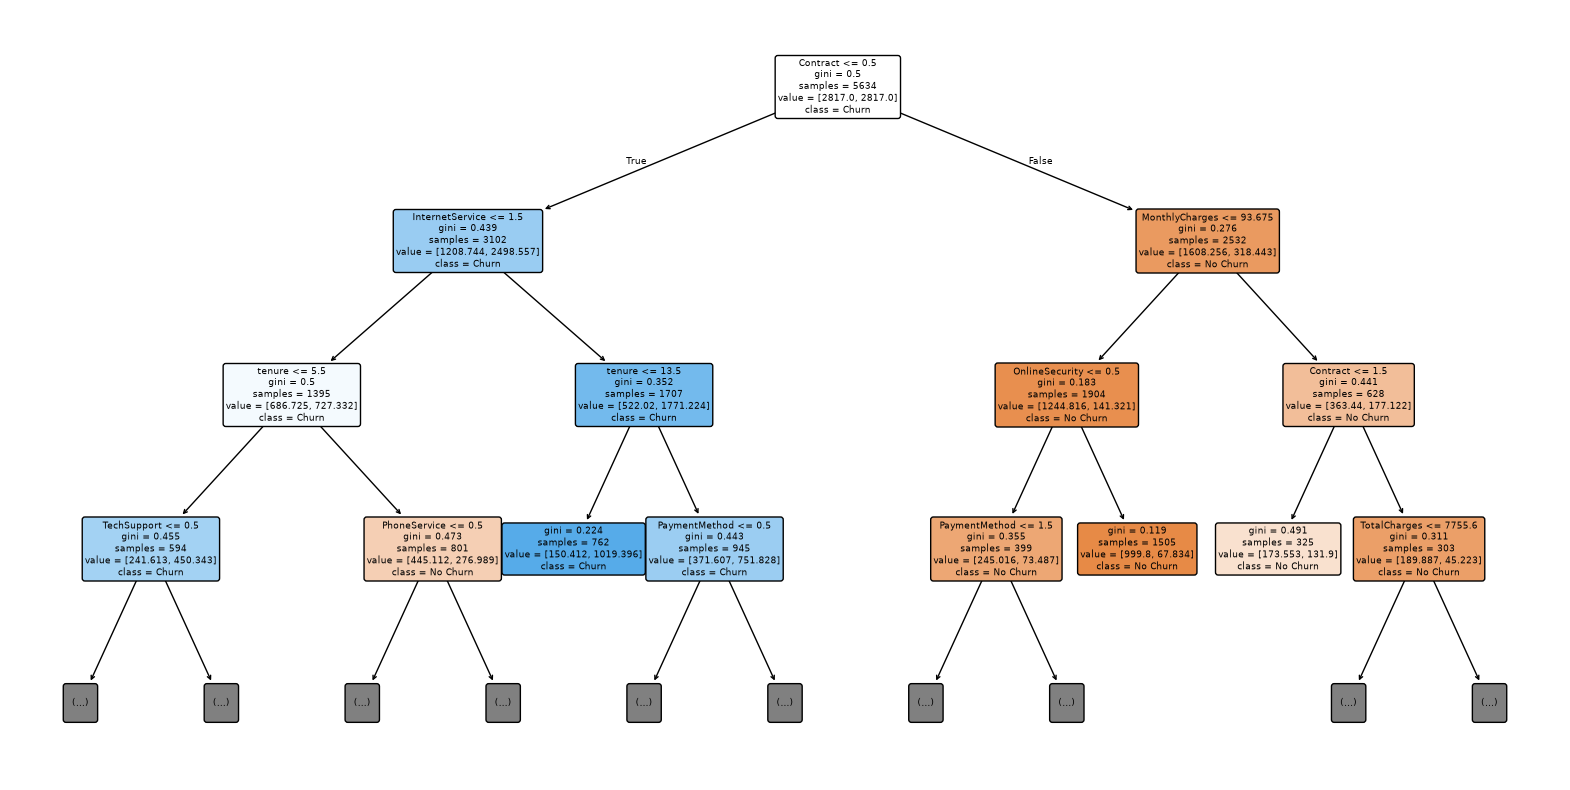

In [44]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    grid.best_estimator_,
    feature_names=X.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.show()

In [45]:
import joblib
import os

os.makedirs("../03_models", exist_ok=True)

joblib.dump(model, "../03_models/decision_tree_model.pkl")

print("Model saved successfully")

Model saved successfully


In [46]:
import joblib

loaded_model = joblib.load("../03_models/decision_tree_model.pkl")

y_pred = loaded_model.predict(X_test)

In [47]:
import joblib

loaded_model = joblib.load(
    "../03_models/decision_tree_model.pkl"
)

new_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(new_customer)

if prediction[0] == 1:
    print("Customer is likely to churn")
else:
    print("Customer is likely to stay")

Customer is likely to stay
